# 8.1 Устройство графика в Matplotlib — код страницы

Аналитика 101 · блок «Дата аналитика» · тема 08 «Визуализация в Python» · страница 8.1.

В ноутбуке весь код страницы. Сначала оба кода из «Анатомии графика»: один и тот же рисунок в объектном стиле и в стиле pyplot. Затем четыре блока раздела «Код»: график для публикации, сетка 2 × 2, функция-шаблон со стилем, pandas и seaborn. В конце четыре нюанса: dpi, шрифты и кириллица, даты на оси, второй `plt.plot`. Данные учебные: выручка магазина из общего набора темы `data/viz/` и дневные метрики из набора темы 07 `data/eda/`.

**Как работать.** Выполняйте ячейки по порядку сверху вниз: блоки раздела «Код» и нюансы пользуются таблицами `sales` и `t` из «Анатомии».

Вывод получен на Python 3.13, pandas 3.0, matplotlib 3.10 и seaborn 0.13.

## Где лежат данные

Код страницы читает файлы по пути от корня папки с материалами: `data/viz/sales_monthly.csv` и `data/eda/daily_metrics.csv`. Ноутбук лежит в папке страницы, поэтому первая ячейка поднимается до папки, в которой есть `data/`, и делает её рабочей.

Туда же код сохранит свои картинки: `anatomy.png`, `revenue_yoy.png` и `.svg`, `grid.png`, папку `charts/` с десятью графиками и ещё десяток файлов из нюансов. Последняя ячейка ноутбука показывает их список.

In [1]:
import os
import pathlib
import platform

import matplotlib
import pandas as pd
import seaborn

root = pathlib.Path.cwd()
while not (root / "data" / "viz").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/viz/
assert (root / "data" / "viz" / "sales_monthly.csv").exists(), \
    "Не найдена папка data/viz/. Скачайте общий набор темы 08 и положите data/ рядом с папкой страницы"
assert (root / "data" / "eda" / "daily_metrics.csv").exists(), \
    "Не найдена папка data/eda/. Для дат на оси нужен ещё общий набор темы 07"
os.chdir(root)
before = {p.name for p in root.iterdir()}   # что лежало в папке до запуска кода

print("Python", platform.python_version(), "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| seaborn", seaborn.__version__)

Python 3.13.18 | pandas 3.0.5 | matplotlib 3.10.0 | seaborn 0.13.2


## Анатомия графика: один рисунок двумя стилями

Первый код называет фигуру и оси явно и вызывает методы осей. Второй обращается к «текущим» фигуре и осям через `plt`. Рисунок получается один и тот же.

### Объектный стиль: фигура и оси названы явно

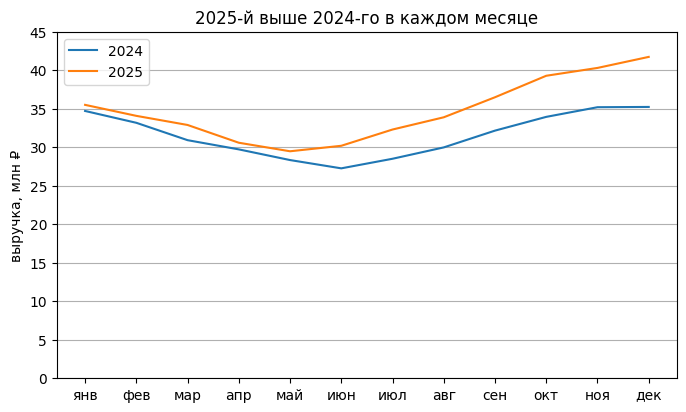

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

sales = pd.read_csv("data/viz/sales_monthly.csv")
sales["year"] = sales["month"].str[:4]            # "2024-03" → "2024"
sales["m"] = sales["month"].str[5:].astype(int)   # "2024-03" → 3
t = sales.pivot_table(index="m", columns="year",
                      values="revenue", aggfunc="sum") / 1e6   # млн ₽
MONTHS = "янв фев мар апр май июн июл авг сен окт ноя дек".split()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t.index, t["2024"], label="2024")
ax.plot(t.index, t["2025"], label="2025")
ax.set_xticks(t.index, MONTHS)
ax.set_ylim(0, 45)
ax.grid(axis="y")
ax.set_title("2025-й выше 2024-го в каждом месяце")
ax.set_ylabel("выручка, млн ₽")
ax.legend()
fig.savefig("anatomy.png")

### Стиль pyplot: команды обращаются к текущим фигуре и осям

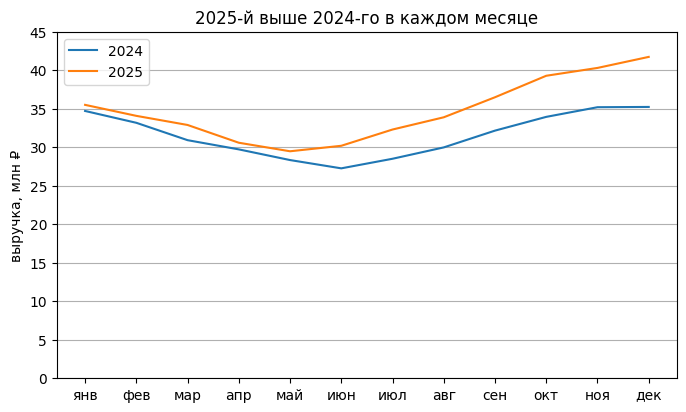

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

sales = pd.read_csv("data/viz/sales_monthly.csv")
sales["year"] = sales["month"].str[:4]            # "2024-03" → "2024"
sales["m"] = sales["month"].str[5:].astype(int)   # "2024-03" → 3
t = sales.pivot_table(index="m", columns="year",
                      values="revenue", aggfunc="sum") / 1e6   # млн ₽
MONTHS = "янв фев мар апр май июн июл авг сен окт ноя дек".split()

plt.figure(figsize=(8, 4.5))
plt.plot(t.index, t["2024"], label="2024")
plt.plot(t.index, t["2025"], label="2025")
plt.xticks(t.index, MONTHS)
plt.ylim(0, 45)
plt.grid(axis="y")
plt.title("2025-й выше 2024-го в каждом месяце")
plt.ylabel("выручка, млн ₽")
plt.legend()
plt.savefig("anatomy_pyplot.png")

Проверка утверждения страницы: файлы двух кодов совпадают попиксельно.

In [4]:
a, b = plt.imread("anatomy.png"), plt.imread("anatomy_pyplot.png")
print(f"anatomy.png: {a.shape[1]} × {a.shape[0]} px | anatomy_pyplot.png: {b.shape[1]} × {b.shape[0]} px")
print("различающихся пикселей:", int((a != b).any(axis=2).sum()) if a.shape == b.shape else "размеры разные")

anatomy.png: 800 × 450 px | anatomy_pyplot.png: 800 × 450 px
различающихся пикселей: 0


## Код: от данных до файла

### С нуля до публикации: данные → фигура → оси → подписи → файл

m       1     5     6     12
year                        
2024  34.7  28.3  27.3  35.2
2025  35.5  29.5  30.2  41.7
рост с июня: 10.7% … 18.4%
revenue_yoy.png 76 КБ
revenue_yoy.svg 16 КБ


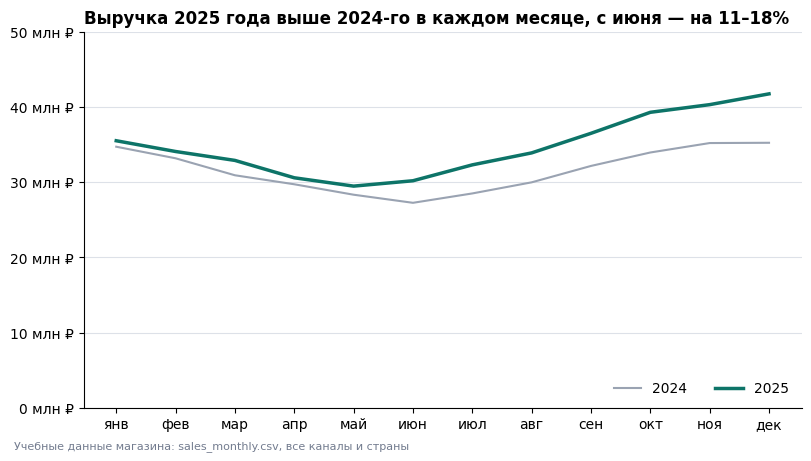

In [5]:
import os

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["svg.fonttype"] = "none"   # в SVG текст остаётся текстом, а не кривыми

# 1. Данные: 960 строк «месяц × канал × страна» → таблица «месяц × год», млн ₽
sales = pd.read_csv("data/viz/sales_monthly.csv")
sales["year"] = sales["month"].str[:4]
sales["m"] = sales["month"].str[5:].astype(int)
t = sales.pivot_table(index="m", columns="year",
                      values="revenue", aggfunc="sum") / 1e6
MONTHS = "янв фев мар апр май июн июл авг сен окт ноя дек".split()

# 2. Фигура и оси — явно, в одну строку
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")

# 3. Данные: прошлый год серым, текущий — акцентом
ax.plot(t.index, t["2024"], color="#9aa3b2", linewidth=1.5, label="2024")
ax.plot(t.index, t["2025"], color="#0d7468", linewidth=2.5, label="2025")

# 4. Оси: деления, пределы, формат подписей
ax.set_xticks(t.index, MONTHS)
ax.set_ylim(0, 50)
ax.yaxis.set_major_formatter("{x:.0f} млн ₽")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#dde1e8")

# 5. Подписи: заголовок-вывод, легенда без рамки, источник
ax.set_title("Выручка 2025 года выше 2024-го в каждом месяце, с июня — на 11–18%",
             loc="left", fontweight="bold")
ax.legend(frameon=False, loc="lower right", ncols=2)
fig.supxlabel("Учебные данные магазина: sales_monthly.csv, все каналы и страны",
              x=0.01, ha="left", fontsize=8, color="#737c8f")   # строка под всей фигурой

# 6. Сохранение: PNG для слайда и письма, SVG для статьи
fig.savefig("revenue_yoy.png", dpi=200)
fig.savefig("revenue_yoy.svg")

growth = t["2025"] / t["2024"] - 1
print(t.round(1).T[[1, 5, 6, 12]])
print(f"рост с июня: {growth.loc[6:].min():.1%} … {growth.loc[6:].max():.1%}")
for f in ("revenue_yoy.png", "revenue_yoy.svg"):
    print(f, round(os.path.getsize(f) / 1024), "КБ")

### Сетка 2 × 2: четыре типа графика и общая ось у каждого столбца

ndarray (2, 2)
общая ось X слева: True
общая ось X справа: True
подписи делений у верхнего левого: False
выше диагонали: 94 из 120, меньше 2 млн: 60


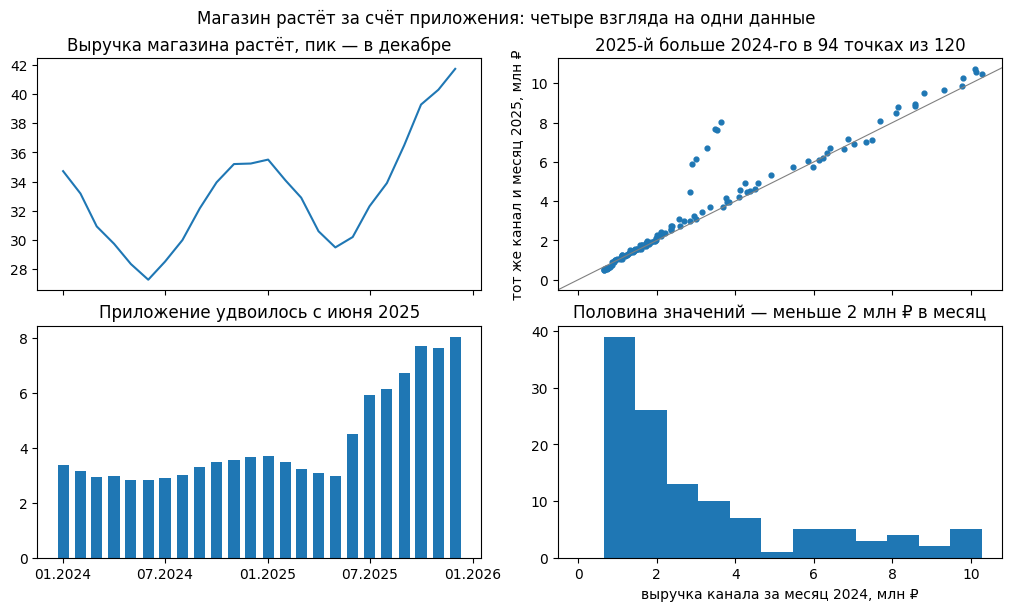

In [6]:
# sales, pd, plt — из кода «Анатомии графика»
import matplotlib.dates as mdates

ym = sales.groupby("month")["revenue"].sum() / 1e6                     # 24 месяца
app = sales[sales["channel"] == "приложение"].groupby("month")["revenue"].sum() / 1e6
dates = pd.to_datetime(ym.index)                                       # строки → даты
cm = sales.pivot_table(index=["channel", "m"], columns="year",
                       values="revenue", aggfunc="sum") / 1e6          # канал × месяц

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex="col", layout="constrained")

axes[0, 0].plot(dates, ym)                                   # линия: динамика
axes[0, 0].set_title("Выручка магазина растёт, пик — в декабре")
axes[1, 0].bar(dates, app, width=20)                         # столбцы: сравнение
axes[1, 0].set_title("Приложение удвоилось с июня 2025")
axes[1, 0].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
axes[1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))     # 01.2025

axes[0, 1].scatter(cm["2024"], cm["2025"], s=12)             # рассеяние: связь
axes[0, 1].axline((0, 0), slope=1, color="grey", linewidth=0.8)
axes[0, 1].set_title("2025-й больше 2024-го в 94 точках из 120")
axes[0, 1].set_ylabel("тот же канал и месяц 2025, млн ₽")
axes[1, 1].hist(cm["2024"], bins=12)                         # гистограмма: распределение
axes[1, 1].set_title("Половина значений — меньше 2 млн ₽ в месяц")
axes[1, 1].set_xlabel("выручка канала за месяц 2024, млн ₽")

fig.suptitle("Магазин растёт за счёт приложения: четыре взгляда на одни данные")   # заголовок фигуры
fig.savefig("grid.png", dpi=150)

print(type(axes).__name__, axes.shape)
print("общая ось X слева:", axes[0, 0].get_xlim() == axes[1, 0].get_xlim())
print("общая ось X справа:", axes[0, 1].get_xlim() == axes[1, 1].get_xlim())
print("подписи делений у верхнего левого:", axes[0, 0].xaxis.get_tick_params()["labelbottom"])
print(f"выше диагонали: {(cm['2025'] > cm['2024']).sum()} из {len(cm)}, меньше 2 млн: {(cm['2024'] < 2).sum()}")

### Функция-шаблон и стиль учебника: десять одинаковых графиков за один цикл

In [7]:
# sales, MONTHS — из кода «Анатомии графика»
from pathlib import Path

from cycler import cycler

TEXTBOOK = {                                   # стиль учебника: один словарь rcParams
    "figure.figsize": (7, 3.4),
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#737c8f",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#dde1e8",
    "axes.prop_cycle": cycler(color=["#9aa3b2", "#0d7468"]),
    "legend.frameon": False,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
}


def yoy_chart(ax, t, title, unit="млн ₽"):
    """Год к году: линия на каждый год, месяцы по оси X, запятая в дробях."""
    for year in t.columns:
        ax.plot(t.index, t[year], label=year, linewidth=2.5 if year == t.columns[-1] else 1.5)
    ax.set_xticks(t.index, MONTHS)
    ax.set_ylim(0, t.max().max() * 1.2)
    ax.yaxis.set_major_formatter(lambda x, pos: f"{x:g}".replace(".", ","))
    ax.set_ylabel(unit)
    ax.set_title(title)
    ax.legend(loc="lower right", ncols=2)
    return ax


by_ch = sales.pivot_table(index=["channel", "m"], columns="year",
                          values="revenue", aggfunc="sum") / 1e6
Path("charts").mkdir(exist_ok=True)
with plt.style.context(TEXTBOOK):              # стиль действует только внутри with
    for i, ch in enumerate(by_ch.index.unique("channel")):
        tc = by_ch.loc[ch]
        delta = round(tc["2025"].sum() / tc["2024"].sum() - 1, 2) + 0   # + 0 убирает «−0»
        delta = f"{delta:+.0%}".replace("-", "−")
        fig, ax = plt.subplots()
        yoy_chart(ax, tc, f"{ch.capitalize()}: {delta} к 2024 году")
        fig.savefig(f"charts/{i:02d}.png")
        plt.close(fig)                         # десятки фигур не копятся в памяти
        print(f"charts/{i:02d}.png  {ax.get_title(loc='left')}")
print("открытых фигур:", len(plt.get_fignums()))

charts/00.png  Кешбэк-сервисы: +3% к 2024 году
charts/01.png  Колл-центр: −20% к 2024 году


charts/02.png  Маркетплейс: +0% к 2024 году
charts/03.png  Офлайн-точки: +5% к 2024 году
charts/04.png  Партнёры: +8% к 2024 году


charts/05.png  Поиск: +6% к 2024 году
charts/06.png  Приложение: +66% к 2024 году
charts/07.png  Рассылка: +12% к 2024 году


charts/08.png  Сайт: +5% к 2024 году
charts/09.png  Соцсети: +2% к 2024 году
открытых фигур: 0


### Тот же график в pandas и seaborn: обе обёртки возвращают Axes

Axes Axes
seaborn, январь: 34.72 | pandas: 34.72


по умолчанию, январь: 0.87 — среднее 40 строк, полос интервала: 2


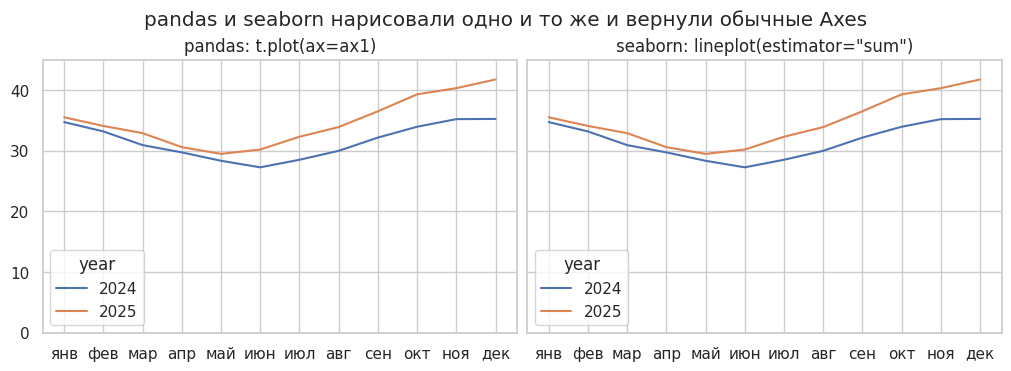

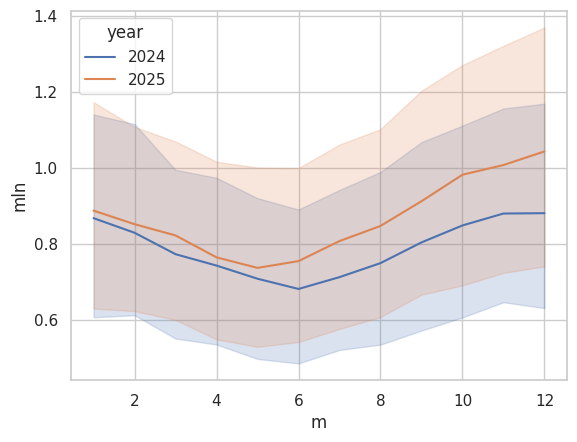

In [8]:
# sales, t, MONTHS — из кода «Анатомии графика»
import seaborn as sns

sns.set_theme(style="whitegrid")       # меняет rcParams: так теперь выглядят все графики
sales["mln"] = sales["revenue"] / 1e6

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, layout="constrained")
t.plot(ax=ax1, title="pandas: t.plot(ax=ax1)")                    # таблица «месяц × год»
sns.lineplot(data=sales, x="m", y="mln", hue="year",               # длинная таблица, 960 строк
             estimator="sum", errorbar=None, ax=ax2)
ax2.set_title('seaborn: lineplot(estimator="sum")')
for ax in (ax1, ax2):
    ax.set_xticks(range(1, 13), MONTHS)
    ax.set_xlabel("")
    ax.set_ylim(0, 45)
fig.suptitle("pandas и seaborn нарисовали одно и то же и вернули обычные Axes")
fig.savefig("pandas_vs_seaborn.png", dpi=150)

print(type(ax1).__name__, type(ax2).__name__)
print("seaborn, январь:", ax2.lines[0].get_ydata()[0].round(2), "| pandas:", t.loc[1, "2024"].round(2))
fig2, ax3 = plt.subplots()
sns.lineplot(data=sales, x="m", y="mln", hue="year", ax=ax3)       # без estimator
print("по умолчанию, январь:", ax3.lines[0].get_ydata()[0].round(2),
      "— среднее 40 строк, полос интервала:", len(ax3.collections))

sns.set_theme меняет rcParams до конца сессии, поэтому и левый график, нарисованный pandas, получил сетку, светлую рамку и крупный шрифт seaborn.

### Возвращаем настройки

На странице каждый блок запускался отдельным скриптом. В ноутбуке сессия одна: `sns.set_theme` поменял `rcParams` до её конца, а блок «С нуля до публикации» оставил текст в SVG текстом. Чтобы нюансы ниже дали те же числа, что на странице, возвращаем настройки Matplotlib по умолчанию.

In [9]:
differ = lambda: sorted(k for k, v in plt.rcParams.items()
                        if v != matplotlib.rcParamsDefault[k] and k != "interactive")   # interactive — режим Jupyter, не оформление
print("настроек оформления, отличных от умолчания:", len(differ()))
plt.rcdefaults()
print("после plt.rcdefaults():", len(differ()))

настроек оформления, отличных от умолчания: 34
после plt.rcdefaults(): 0


## Четыре нюанса

### Один figsize, разные dpi: сколько пикселей в PNG

figsize: [8.  4.5] дюйма, dpi фигуры: 100.0
PNG, dpi= 72: 576×324 px, 14 КБ
PNG, dpi=100: 800×450 px, 22 КБ
PNG, dpi=200: 1600×900 px, 54 КБ


PNG, bbox_inches='tight': 667×412 px — пустые поля обрезаны


SVG: 19 КБ, 576×324 pt, чёткий при любом масштабе


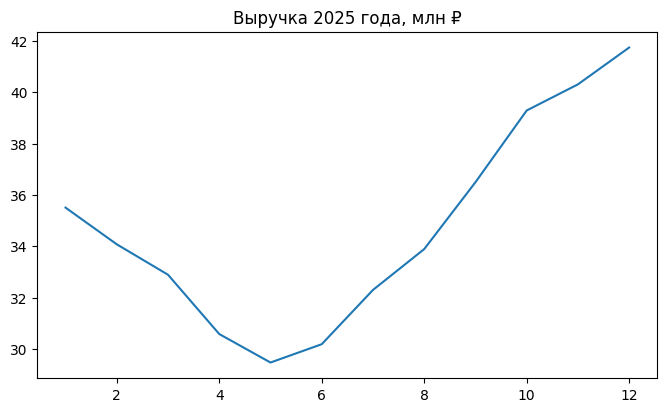

In [10]:
# t — из кода «Анатомии графика»
import os

fig, ax = plt.subplots(figsize=(8, 4.5))      # размер в дюймах
ax.plot(t.index, t["2025"])
ax.set_title("Выручка 2025 года, млн ₽")
print("figsize:", fig.get_size_inches(), "дюйма, dpi фигуры:", fig.dpi)

for dpi in (72, 100, 200):
    fig.savefig(f"chart_{dpi}.png", dpi=dpi)
    h, w, _ = plt.imread(f"chart_{dpi}.png").shape
    print(f"PNG, dpi={dpi:>3}: {w}×{h} px, {os.path.getsize(f'chart_{dpi}.png') / 1024:.0f} КБ")

fig.savefig("chart_tight.png", bbox_inches="tight")
h, w, _ = plt.imread("chart_tight.png").shape
print(f"PNG, bbox_inches='tight': {w}×{h} px — пустые поля обрезаны")

fig.savefig("chart.svg")
print(f"SVG: {os.path.getsize('chart.svg') / 1024:.0f} КБ, 576×324 pt, чёткий при любом масштабе")

### Кириллица: шрифта нет — подмена, глифа нет — квадратики

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (38 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


cmr10: заголовок нарисован, буквы — пустыми квадратами


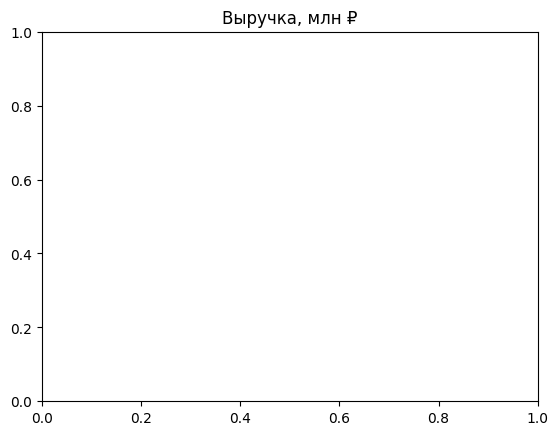

/usr/local/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1042 (\N{CYRILLIC CAPITAL LETTER VE}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)


/usr/local/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1099 (\N{CYRILLIC SMALL LETTER YERU}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1088 (\N{CYRILLIC SMALL LETTER ER}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1091 (\N{CYRILLIC SMALL LETTER U}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1095 (\N{CYRILLIC SMALL LETTER CHE}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 1082 (\N{CYRILLIC SMALL LETTER KA}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/li

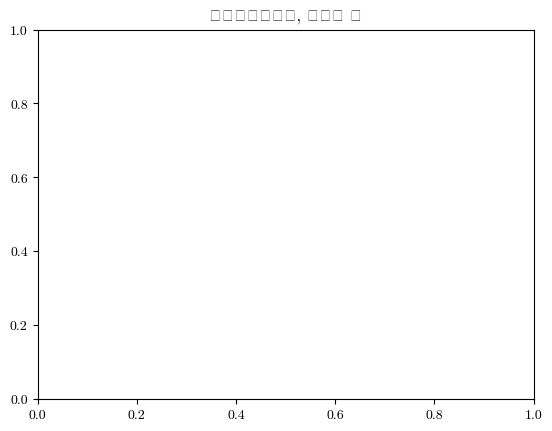

In [11]:
# plt — из кода «Анатомии графика»
from pathlib import Path

import matplotlib as mpl
from matplotlib import font_manager

print("по умолчанию:", Path(font_manager.findfont("DejaVu Sans")).name)

with mpl.rc_context({"font.family": "Arial"}):     # такого шрифта в системе нет
    fig, ax = plt.subplots()
    ax.set_title("Выручка, млн ₽")
    fig.canvas.draw()
    print("вместо Arial:", ax.title.get_fontname())

with mpl.rc_context({"font.family": "cmr10"}):     # шрифт есть, но без кириллицы
    fig, ax = plt.subplots()
    ax.set_title("Выручка, млн ₽")
    fig.canvas.draw()
    print("cmr10: заголовок нарисован, буквы — пустыми квадратами")

В ноутбуке предупреждений больше, чем на странице: в конце ячейки Jupyter рисует обе фигуры ещё раз, чтобы показать их, и Matplotlib снова не находит Arial и кириллицу в cmr10. Путь перед `UserWarning` тоже другой — временный файл ячейки вместо `fonts.py`.

### Даты на оси: строки против дат

str 86


делений сверху: 86 | снизу: 7


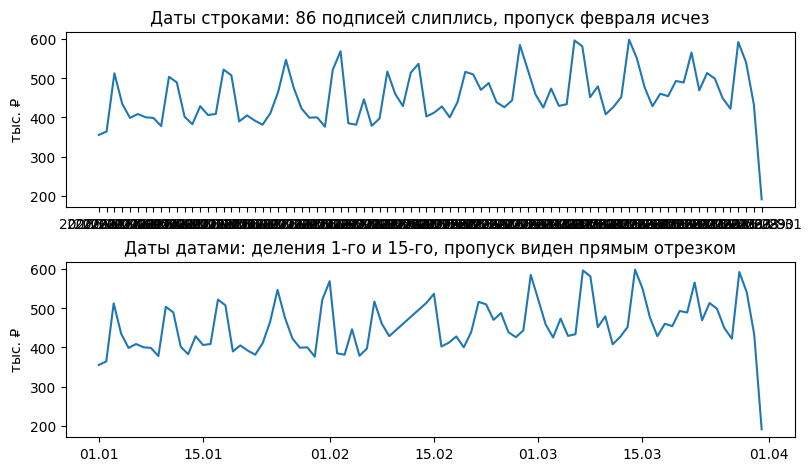

In [12]:
# plt, pd — из кода «Анатомии графика»
import matplotlib.dates as mdates

d = pd.read_csv("data/eda/daily_metrics.csv")   # 86 дней, 10–13 февраля выгрузка потеряна
print(d["date"].dtype, len(d))

fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 4.6), layout="constrained")
top.plot(d["date"], d["revenue"] / 1e3)            # строки: каждая дата — отдельная категория
top.set_title("Даты строками: 86 подписей слиплись, пропуск февраля исчез")

d["date"] = pd.to_datetime(d["date"])              # теперь это даты
bottom.plot(d["date"], d["revenue"] / 1e3)
bottom.xaxis.set_major_locator(mdates.MonthLocator(bymonthday=[1, 15]))
bottom.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
bottom.set_title("Даты датами: деления 1-го и 15-го, пропуск виден прямым отрезком")
for ax in (top, bottom):
    ax.set_ylabel("тыс. ₽")
fig.savefig("dates.png", dpi=150)

print("делений сверху:", len(top.get_xticks()), "| снизу:", len(bottom.get_xticks()))

### Второй plt.plot ложится на первый график

открытых фигур: [1]
линий на текущих осях: 2
заголовок: 2025


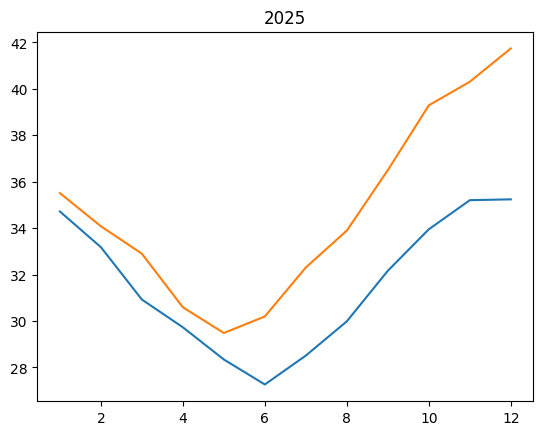

In [13]:
# t — из кода «Анатомии графика»; всё ниже — одна ячейка или один скрипт
plt.plot(t.index, t["2024"])
plt.title("2024")
plt.savefig("y2024.png")

plt.plot(t.index, t["2025"])         # хотели второй, отдельный график
plt.title("2025")
plt.savefig("y2025.png")

print("открытых фигур:", plt.get_fignums())
print("линий на текущих осях:", len(plt.gca().lines))
print("заголовок:", plt.gca().get_title())

Тот же код, разнесённый по двум ячейкам Jupyter, даёт два отдельных графика: в конце ячейки встроенный вывод показывает фигуру и закрывает её.

### Тот же код двумя ячейками

Разнесём две половины последнего блока по разным ячейкам. В конце ячейки встроенный вывод Jupyter показывает фигуру и закрывает её, поэтому второй `plt.plot` создаёт новую фигуру и новые оси.

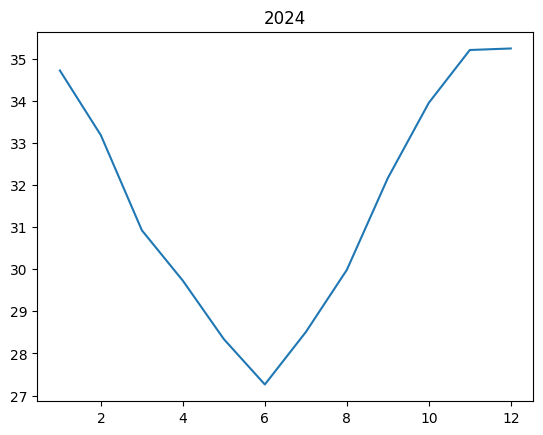

In [14]:
plt.plot(t.index, t["2024"])
plt.title("2024")
plt.savefig("y2024.png")

открытых фигур: [1]
линий на текущих осях: 1
заголовок: 2025


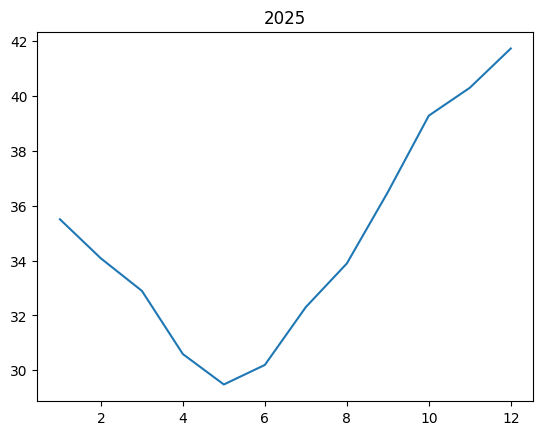

In [15]:
plt.plot(t.index, t["2025"])
plt.title("2025")
plt.savefig("y2025.png")

print("открытых фигур:", plt.get_fignums())
print("линий на текущих осях:", len(plt.gca().lines))
print("заголовок:", plt.gca().get_title())

## Что сохранил код

Файлы и папки, которых не было в корне материалов до запуска ноутбука. Их можно удалить: код создаст их заново.

In [16]:
made = sorted(p.name + ("/" if p.is_dir() else "") for p in root.iterdir() if p.name not in before)
print(len(made), "новых:", ", ".join(made))

15 новых: anatomy.png, anatomy_pyplot.png, chart.svg, chart_100.png, chart_200.png, chart_72.png, chart_tight.png, charts/, dates.png, grid.png, pandas_vs_seaborn.png, revenue_yoy.png, revenue_yoy.svg, y2024.png, y2025.png
